In [1]:
import os, sys
path = os.path.abspath('../../../Processing/')
if(path not in sys.path):
    sys.path.append(path)

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ProcessingPipeline as pp

from HYSERDataLoader import HYSERDataLoader

In [29]:
# Raw Hyser download root (see docs/DATASETS.md). Override with CBEB_DATA_ROOT.
from pathlib import Path as _Path
import os as _os
_pkg = _Path.cwd().resolve()
for _ in range(8):
    if (_pkg / "README.md").exists() and (_pkg / "EMG").exists():
        break
    _pkg = _pkg.parent
_DATA_ROOT = _Path(_os.environ.get("CBEB_DATA_ROOT", _pkg / "data")).resolve()
hyser_path = str(_DATA_ROOT / "HYSER" / "files" / "hd-semg" / "1.0.0" / "pr_dataset")
dataset_name = str(_DATA_ROOT / "hyser_gestures_common_mono")


In [3]:
import glob
glob.glob(hyser_path+"/*")[:10]

['../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject17_session1',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject07_session2',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject01_session2',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject08_session2',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject04_session2',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject05_session2',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject08_session1',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject10_session1',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject20_session1',
 '../../../../../data/HYSER/files/hd-semg/1.0.0/pr_dataset/subject10_session2']

In [4]:
moi = [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 30, 31]# [0, 20, 21, 26, 27, 34 ,31, 30, 2, 33]

In [5]:
len(moi)

12

In [6]:
subjects = [f'0{i}' if i < 10 else str(i) for i in range(1, 21)]
print(subjects)
sessions = [1, 2]

train_rep = [1, 2, 7]
val_rep = [3, 4, 8]
test_rep = [5, 6]

rest_repetition = 1
differential = False  # paper models: monopolar, two 8x8 grids


['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']


In [7]:
# emg_preprocessing = pp.ProcessingPipeline([pp.Retification(),
#                                            pp.EMGTKE(),
#                                            pp.MAFilter(31),
#                                            pp.Norm()])

emg_preprocessing = pp.ProcessingPipeline([pp.Retification(),
                                           pp.EMGTKE(),
                                           pp.MAFilter(31)])

In [9]:
HYSERDataLoader.save_dataset_parameters(
    save_folder=f'{dataset_name}/train',
    moi=moi,
    repetitions=train_rep,
    subjects=subjects,
    sessions=sessions,
    preprocessing=emg_preprocessing,
    rest_repetition=rest_repetition,
    differential=differential,
    dataset_name=dataset_name,
)

for subj in subjects:        
    for sess in sessions:
        data_loader = HYSERDataLoader(base_path=hyser_path,
                                      subject_id=subj,
                                      session_id=sess,
                                      h5dir_name=f'{dataset_name}/train',
                                      preprocessing=emg_preprocessing,
                                      differential=differential,
                                      rest_repetition=rest_repetition)
        data_loader.save_to_h5_file(moi, train_rep)
        del data_loader

In [10]:
HYSERDataLoader.save_dataset_parameters(
    save_folder=f'{dataset_name}/val',
    moi=moi,
    repetitions=val_rep,
    subjects=subjects,
    sessions=sessions,
    preprocessing=emg_preprocessing,
    rest_repetition=rest_repetition,
    differential=differential,
    dataset_name=dataset_name,
)

for subj in subjects:        
    for sess in sessions:
        data_loader = HYSERDataLoader(base_path=hyser_path,
                                      subject_id=subj,
                                      session_id=sess,
                                      h5dir_name=f'{dataset_name}/val',
                                      preprocessing=emg_preprocessing,
                                      differential=differential,
                                      rest_repetition=rest_repetition)
        data_loader.save_to_h5_file(moi, val_rep)
        del data_loader

In [11]:
HYSERDataLoader.save_dataset_parameters(
    save_folder=f'{dataset_name}/test',
    moi=moi,
    repetitions=test_rep,
    subjects=subjects,
    sessions=sessions,
    preprocessing=emg_preprocessing,
    rest_repetition=rest_repetition,
    differential=differential,
    dataset_name=dataset_name,
)

for subj in subjects:        
    for sess in sessions:
        data_loader = HYSERDataLoader(base_path=hyser_path,
                                      subject_id=subj,
                                      session_id=sess,
                                      h5dir_name=f'{dataset_name}/test',
                                      preprocessing=emg_preprocessing,
                                      differential=differential,
                                      rest_repetition=rest_repetition)
        data_loader.save_to_h5_file(moi, test_rep)
        del data_loader

In [12]:
filename = f'{dataset_name}/train/Subject01.hdf5'
h5_file = h5py.File(filename, 'r')

In [13]:
h5_file.keys()

<KeysViewHDF5 ['session_1', 'session_2', 'sessions']>

In [14]:
for r in h5_file['sessions']:
    print(r, end=' ')

1.0 2.0 

In [15]:
h5_file['session_1'].keys()

<KeysViewHDF5 ['gesture_0', 'gesture_1', 'gesture_10', 'gesture_11', 'gesture_2', 'gesture_3', 'gesture_30', 'gesture_31', 'gesture_4', 'gesture_5', 'gesture_6', 'gesture_7', 'gestures']>

In [16]:
h5_file['session_1']['gestures']

<HDF5 dataset "gestures": shape (12,), type "<i8">

In [17]:
h5_file['session_2'].keys()

<KeysViewHDF5 ['gesture_0', 'gesture_1', 'gesture_10', 'gesture_11', 'gesture_2', 'gesture_3', 'gesture_30', 'gesture_31', 'gesture_4', 'gesture_5', 'gesture_6', 'gesture_7', 'gestures']>

In [18]:
list(h5_file['session_1']['gestures'])

[0, 5, 1, 7, 2, 3, 4, 31, 6, 30, 11, 10]

In [19]:
list(h5_file['session_2']['gestures'])

[0, 4, 11, 10, 7, 2, 6, 5, 30, 31, 3, 1]

In [20]:
h5_file['session_1'].keys()

<KeysViewHDF5 ['gesture_0', 'gesture_1', 'gesture_10', 'gesture_11', 'gesture_2', 'gesture_3', 'gesture_30', 'gesture_31', 'gesture_4', 'gesture_5', 'gesture_6', 'gesture_7', 'gestures']>

In [21]:
h5_file['session_1']['gesture_1'].keys()

<KeysViewHDF5 ['repetition_1', 'repetition_2', 'repetition_7', 'repetitions']>

In [22]:
h5_file['session_1']['gesture_1']['repetition_1'].keys()

<KeysViewHDF5 ['emg']>

In [23]:
h5_file['session_1']['gesture_1']['repetitions'][:]

array([1, 2, 7])

In [24]:
h5_file['session_1']['gesture_1']['repetition_1']['emg'].shape

(128, 489)

In [25]:
h5_file['session_1']['gesture_1']['repetition_1'].keys()

<KeysViewHDF5 ['emg']>

In [26]:
h5_file['session_1']['gesture_0'].keys()

<KeysViewHDF5 ['repetition_0', 'repetition_1', 'repetition_10', 'repetition_11', 'repetition_12', 'repetition_13', 'repetition_14', 'repetition_15', 'repetition_16', 'repetition_17', 'repetition_18', 'repetition_19', 'repetition_2', 'repetition_20', 'repetition_21', 'repetition_22', 'repetition_23', 'repetition_24', 'repetition_25', 'repetition_26', 'repetition_27', 'repetition_28', 'repetition_29', 'repetition_3', 'repetition_30', 'repetition_31', 'repetition_32', 'repetition_4', 'repetition_5', 'repetition_6', 'repetition_7', 'repetition_8', 'repetition_9', 'repetitions']>

(128, 835)


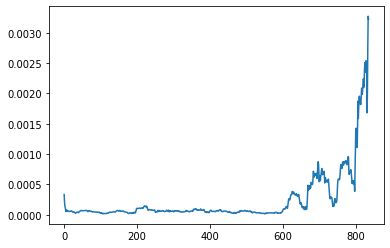

In [27]:
emg_rest = h5_file['session_1']['gesture_0']['repetition_1']['emg']
print(emg_rest.shape)  # (canais, samples) → aqui (128, 613)
plt.plot(range(emg_rest.shape[1]), emg_rest[0, :])

ValueError: x and y must have same first dimension, but have shapes (506,) and (489,)

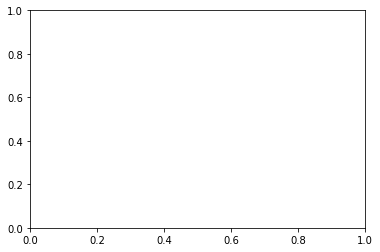

In [28]:
plt.plot(range(506), h5_file['session_1']['gesture_1']['repetition_1']['emg'][0,:])

In [ ]:
for rep in h5_file['session_1']['gesture_1']:
    if(rep != 'repetitions'):
        plt.title(f'Session 1, Gesture 1, Repetition {rep[-1]}')
        plt.plot(range(h5_file['session_1']['gesture_1'][rep]['emg'].shape[1]), 
                 h5_file['session_1']['gesture_1'][rep]['emg'][0,:])
        plt.show()